# Individual-task training curves and AUC

This notebook compares the three separately trained tasks for every algorithm in `../dispatch/experiments/individual`. It reads matching CSVs in `output/projects` and calls `plot_iqm.py`'s compute-only function, `compute_plot_data`.

Each curve is the mean episodic return across available seeds at each evaluation timestep; the band is ±1 standard error. AUC is trapezoidal integration of that curve over its observed timestep range. The table also shows AUC divided by the observed duration. Return scales differ by environment, so compare within an environment. Missing runs remain visible in the coverage report.

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'scripts' / 'plot_iqm.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts' / 'plot_iqm.py').exists(), 'Open from the repository or scripts directory.'
sys.path.insert(0, str(ROOT / 'scripts'))
from plot_iqm import compute_plot_data

DISPATCH = ROOT / 'dispatch' / 'experiments' / 'individual'
DATA = ROOT / 'output' / 'projects'
TASK_IDS = (0, 1, 2)
AGGREGATION = 'mean'
configs = {p.stem: yaml.safe_load(p.read_text()) for p in sorted(DISPATCH.glob('*.yaml'))}
print(f'Found {len(configs)} dispatched algorithm/environment pairs.')

Found 4 dispatched algorithm/environment pairs.


In [2]:
inventory = []
curve_parts = []
for name, spec in configs.items():
    project = spec["project"]
    folder = DATA / project
    seed_sets = {}
    for task in TASK_IDS:
        pattern = re.compile(rf"^{re.escape(project)}-s_(\d+)-task-{task}\.csv$")
        seeds = sorted(int(match.group(1)) for file in folder.glob("*.csv")
                       if (match := pattern.fullmatch(file.name)))
        seed_sets[task] = seeds
        inventory.append({
            "project": project,
            "algorithm": spec["algorithm"].upper(),
            "environment": spec["env"],
            "task": task + 1,
            "files": len(seeds),
            "seeds": ", ".join(map(str, seeds)) if seeds else "—",
        })
    all_seeds = sorted(set().union(*seed_sets.values()))
    if not all_seeds:
        continue
    plot_config = {
        "defaults": {
            "seeds": all_seeds,
            "timesteps": spec["total_timesteps"],
            "aggregation": AGGREGATION,
            "output_file": f"{project}_individual_auc",
        },
        "plots": [{
            "title": project,
            "lines": [{
                "method": f"projects/{project}/{project}-s_<s>-task-{task}",
                "label": f"Task {task + 1}",
                "test_env": "0",
                "num_tasks": 1,
                "smooth": None,
            } for task in TASK_IDS],
        }],
    }
    # Equivalent to plot_iqm.py --config ... --compute-only, with cache
    # disabled so the discovered seed set is always used.
    part = compute_plot_data(plot_config, use_cache=False)
    if not part.empty:
        part["algorithm"] = spec["algorithm"].upper()
        part["environment"] = spec["env"]
        part["task"] = part["line_index"] + 1
        part["project"] = project
        curve_parts.append(part)

coverage = pd.DataFrame(inventory)
curves = pd.concat(curve_parts, ignore_index=True) if curve_parts else pd.DataFrame()
display(coverage)
print(f"Computed {len(curves):,} curve points across {len(curve_parts)} available projects.")

Computing mean for Task 1 on 0...
Computing mean for Task 2 on 0...
Computing mean for Task 3 on 0...
Computing mean for Task 1 on 0...
Computing mean for Task 2 on 0...
Computing mean for Task 3 on 0...
Computing mean for Task 1 on 0...
Computing mean for Task 2 on 0...
Computing mean for Task 3 on 0...


,project,algorithm,environment,task,files,seeds
0,ddpg_ip_individual,DDPG,inverted_pendulum,1,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
1,ddpg_ip_individual,DDPG,inverted_pendulum,2,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
2,ddpg_ip_individual,DDPG,inverted_pendulum,3,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
3,dqn_cp_individual,DQN,cartpole,1,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
4,dqn_cp_individual,DQN,cartpole,2,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
5,dqn_cp_individual,DQN,cartpole,3,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
6,sac_ip_individual,SAC,inverted_pendulum,1,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
7,sac_ip_individual,SAC,inverted_pendulum,2,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
8,sac_ip_individual,SAC,inverted_pendulum,3,10,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"
9,sacd_cp_individual,SACD,cartpole,1,0,—


Computed 2,400 curve points across 3 available projects.


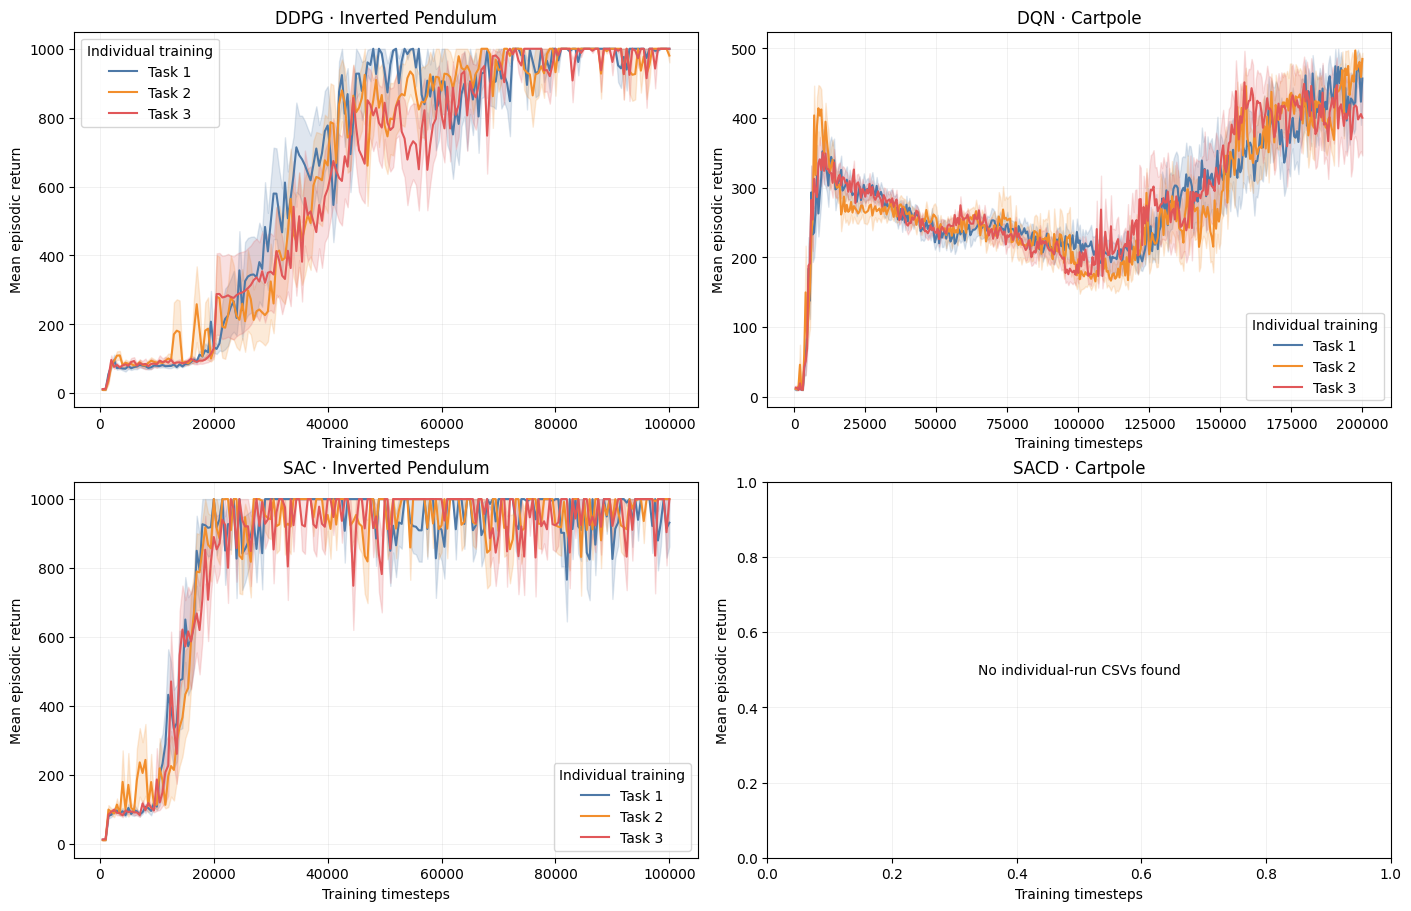

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
colors = {1: "#4E79A7", 2: "#F28E2C", 3: "#E15759"}
for ax, (name, spec) in zip(axes.flat, configs.items()):
    subset = curves[curves["project"] == name] if not curves.empty else pd.DataFrame()
    for task in (1, 2, 3):
        line = subset[subset["task"] == task].sort_values("timestep") if not subset.empty else pd.DataFrame()
        if line.empty:
            continue
        x = line["timestep"].to_numpy(dtype=float)
        ax.plot(x, line["center"].to_numpy(dtype=float), label=f"Task {task}", color=colors[task], lw=1.5)
        ax.fill_between(x, line["lower"].to_numpy(dtype=float),
                        line["upper"].to_numpy(dtype=float), color=colors[task], alpha=0.18)
    ax.set(title=f'{spec["algorithm"].upper()} · {spec["env"].replace("_", " ").title()}',
           xlabel="Training timesteps", ylabel="Mean episodic return")
    ax.grid(alpha=0.25)
    if subset.empty:
        ax.text(0.5, 0.5, "No individual-run CSVs found", ha="center", va="center",
                transform=ax.transAxes)
    else:
        ax.legend(title="Individual training")
plt.show()

In [4]:
auc_rows = []
for _, row in coverage.iterrows():
    line = curves[(curves["project"] == row["project"]) & (curves["task"] == row["task"])] if not curves.empty else pd.DataFrame()
    result = {key: row[key] for key in ["algorithm", "environment", "task", "files"]}
    if line.empty:
        auc_rows.append({**result, "points": 0, "start_step": np.nan, "end_step": np.nan,
                         "auc_return_steps": np.nan, "mean_return_over_range": np.nan,
                         "status": "no curve"})
        continue
    line = line.sort_values("timestep")
    x = line["timestep"].to_numpy(dtype=float)
    y = line["center"].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    assert len(x) >= 2 and np.all(np.diff(x) > 0), "AUC needs at least two ordered evaluation points."
    area = float(np.trapezoid(y, x))
    auc_rows.append({**result, "points": len(x), "start_step": x[0], "end_step": x[-1],
                     "auc_return_steps": area, "mean_return_over_range": area / (x[-1] - x[0]),
                     "status": "ok"})
auc = pd.DataFrame(auc_rows)
display(auc.style.format({
    "start_step": "{:,.0f}", "end_step": "{:,.0f}",
    "auc_return_steps": "{:,.0f}", "mean_return_over_range": "{:,.2f}",
}, na_rep="—"))
print("AUC integrates the mean curve over observed evaluation steps; it does not extrapolate to step zero or the configured horizon.")

,algorithm,environment,task,files,points,start_step,end_step,auc_return_steps,mean_return_over_range,status
0,DDPG,inverted_pendulum,1,10,200,500,"100,000","66,894,922",672.31,ok
1,DDPG,inverted_pendulum,2,10,200,500,"100,000","64,885,225",652.11,ok
2,DDPG,inverted_pendulum,3,10,200,500,"100,000","62,372,392",626.86,ok
3,DQN,cartpole,1,10,400,500,"200,000","56,396,565",282.69,ok
4,DQN,cartpole,2,10,400,500,"200,000","55,683,005",279.11,ok
5,DQN,cartpole,3,10,400,500,"200,000","57,085,117",286.14,ok
6,SAC,inverted_pendulum,1,10,200,500,"100,000","83,451,992",838.71,ok
7,SAC,inverted_pendulum,2,10,200,500,"100,000","82,995,887",834.13,ok
8,SAC,inverted_pendulum,3,10,200,500,"100,000","82,533,865",829.49,ok
9,SACD,cartpole,1,0,0,—,—,—,—,no curve


AUC integrates the mean curve over observed evaluation steps; it does not extrapolate to step zero or the configured horizon.


In [5]:
# Compare only returns measured in the same environment.
comparison = auc.pivot_table(
    index=["environment", "task"],
    columns="algorithm",
    values="mean_return_over_range",
    aggfunc="first",
    dropna=False,
)
display(comparison.style.format("{:,.2f}", na_rep="—"))

EXPORT = ROOT / "output" / "plots" / "individual"
EXPORT.mkdir(parents=True, exist_ok=True)
curves.to_csv(EXPORT / "individual_training_curves_data.csv", index=False)
auc.to_csv(EXPORT / "individual_training_auc.csv", index=False)
print(f"Saved curve data and AUC table in {EXPORT}")

Saved curve data and AUC table in /home/seb/Code/uni/stability-gap-drl/output/plots/individual
